# Đánh giá các mạng đã train (cấp 5 và 6)

Notebook này gồm 3 phần:

1. **Đường cong huấn luyện** đọc từ log có sẵn (`metrics.json` của SL, `metrics.jsonl` của RL) — chạy tức thì, không đánh ván nào.
2. **Đánh giá thử** các checkpoint: mỗi checkpoint đấu `N_EVAL_GAMES` ván với L2 và L3 (đổi màu, cùng khai cuộc cho mọi checkpoint). Kết quả được **lưu cache** vào `runs/train_eval/results.csv`, chạy lại notebook chỉ đánh những checkpoint hoặc đối thủ mới.
3. **Kiểm tra value head** (MSE theo bên đi) để chắc quy ước dấu đúng.

Chạy từ gốc dự án; cần `uv sync --extra analysis` (pandas, matplotlib) và PyTorch.

In [1]:
import os
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
os.chdir(ROOT)   # mọi đường dẫn tương đối tính từ gốc dự án

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from caro.nn.model import CaroResNet

pd.options.display.float_format = "{:.3f}".format
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

def style(ax, grid="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)

## 1. Cấu hình

In [2]:
# Các run RL cần so sánh: tên hiển thị -> thư mục run (trong runs/train/pg_policy/)
RL_RUNS = {
    "RL từ SL v2": "20261117-224555_v2_init",
    "RL từ SL v3": "20261118-125103_v3_init",
}
# Các run SL: tên hiển thị -> thư mục (trong runs/train/)
SL_RUNS = {"SL v1": "sl_policy", "SL v2": "sl_policy_v2", "SL v3": "sl_policy_v3"}

# Checkpoint đem đi đánh giá thử: tên hiển thị -> đường dẫn .pt
CHECKPOINTS = {
    "SL v1": "runs/train/sl_policy/latest.pt",
    "SL v2": "runs/train/sl_policy_v2/latest.pt",
    "SL v3": "runs/train/sl_policy_v3/latest.pt",
    "RL v2 best": "runs/train/pg_policy/20261117-224555_v2_init/checkpoints/best.pt",
    "RL v3 best": "runs/train/pg_policy/20261118-125103_v3_init/checkpoints/best.pt",
    "RL v3 last": "runs/train/pg_policy/20261118-125103_v3_init/checkpoints/last.pt",
}
OPPONENTS = ["agents/l2_rule", "agents/l3_alphabeta"]   # L3: độ sâu mặc định 6, lõi Cython nếu đã build
N_EVAL_GAMES = 100       # ván mỗi cặp (chẵn: một nửa mỗi bên đi trước)
EVAL_SEED = 2026
FORCE = False            # True = đánh lại, bỏ qua cache

CACHE = Path("runs/train_eval/results.csv")
CACHE.parent.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("thiết bị:", DEVICE)

thiết bị: cuda


## 2. Đường cong huấn luyện

### 2.1 Học có giám sát (loss train / val theo epoch)

Loss gồm CE(policy) + MSE(value). Train ≈ val nghĩa là chưa overfit; val còn đi xuống nghĩa là còn học thêm được.

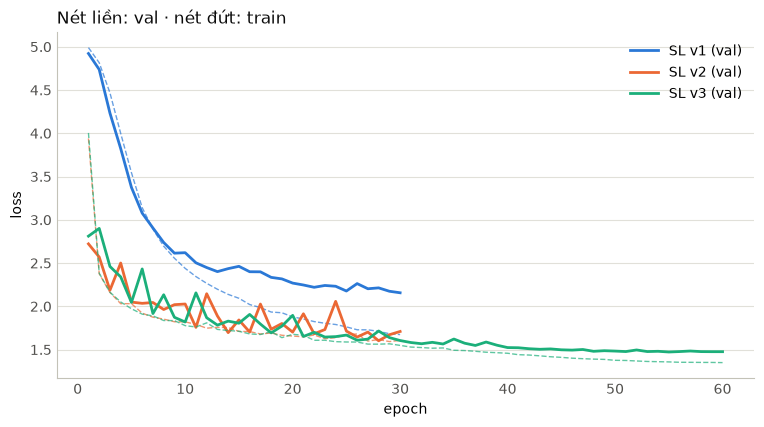

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (name, d) in enumerate(SL_RUNS.items()):
    p = Path("runs/train") / d / "metrics.json"
    if not p.exists():
        continue
    m = pd.DataFrame(json.loads(p.read_text(encoding="utf-8")))
    ax.plot(m.epoch, m.val_loss, color=PALETTE[i], lw=2, label=f"{name} (val)")
    ax.plot(m.epoch, m.train_loss, color=PALETTE[i], lw=1, ls="--", alpha=0.7)
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(frameon=False); style(ax)
ax.set_title("Nét liền: val · nét đứt: train", color=INK, loc="left")
plt.show()

### 2.2 RL: điểm đánh giá định kỳ vs L2 và L3

Mỗi chấm là một lần đánh giá (argmax, 100 ván); vạch là khoảng tin cậy Wilson 95%. Vạch chồng nhau nghĩa là chưa phân biệt được.

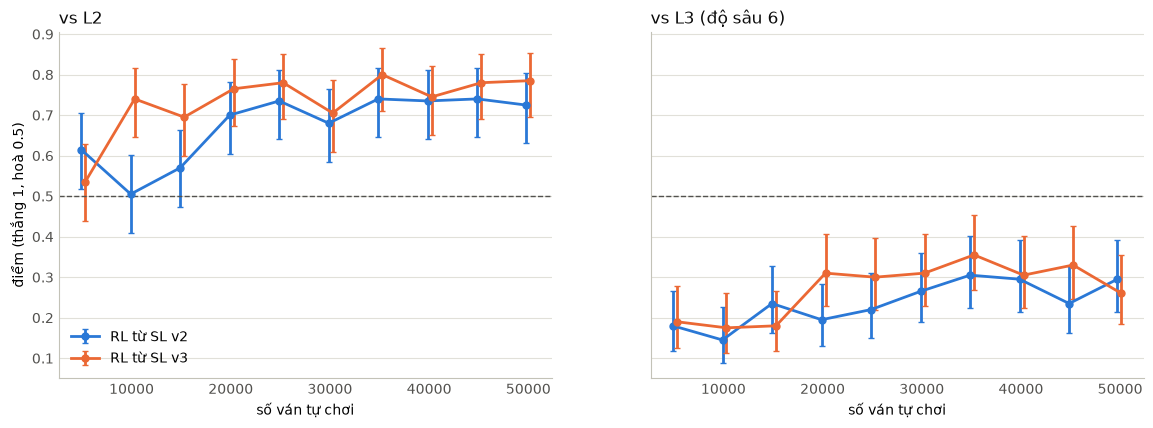

In [4]:
def load_rl(run):
    rows = [json.loads(line) for line in (Path("runs/train/pg_policy") / run / "metrics.jsonl").open(encoding="utf-8")]
    return pd.DataFrame([r for r in rows if r.get("eval")]), pd.DataFrame([r for r in rows if not r.get("eval")])

rl_eval, rl_train = {}, {}
for name, run in RL_RUNS.items():
    rl_eval[name], rl_train[name] = load_rl(run)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, opp, title in zip(axes, ("L2-Rule", "L3-AlphaBeta"), ("vs L2", "vs L3 (độ sâu 6)"), strict=True):
    for i, (name, e) in enumerate(rl_eval.items()):
        lo, hi = e[f"{opp}_ci_low"], e[f"{opp}_ci_high"]
        ax.errorbar(e.step + (i - 0.5) * 400, e[f"{opp}_score"], yerr=[e[f"{opp}_score"] - lo, hi - e[f"{opp}_score"]],
                    color=PALETTE[i], lw=2, marker="o", ms=5, capsize=2, label=name)
    ax.axhline(0.5, color=MUTED, ls="--", lw=1)
    ax.set_title(title, color=INK, loc="left"); ax.set_xlabel("số ván tự chơi"); style(ax)
axes[0].set_ylabel("điểm (thắng 1, hoà 0.5)"); axes[0].legend(frameon=False)
plt.show()

### 2.3 RL: `value_loss`, entropy và điểm so với pool

- `value_loss` cao (> 0.9) lúc đầu nghĩa là value head sai quy ước dấu (xem `docs/GHI_CHU_value_head.md`).
- Entropy giảm = policy sắc dần.
- `train_win_vs_pool` ≈ 0.5 nghĩa là bản mới và các bản cũ trong pool ngang sức.

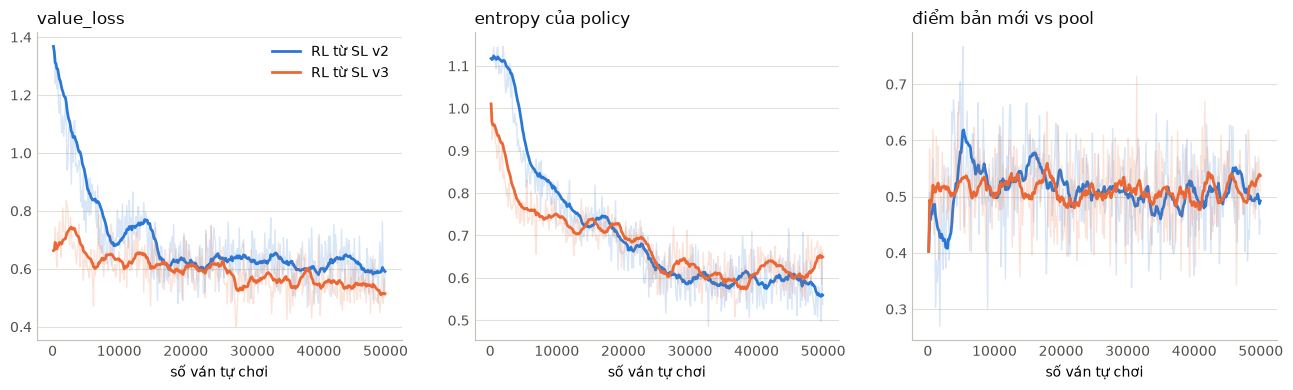

In [5]:
def smooth(s, w=15):
    return s.rolling(w, min_periods=1).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ("value_loss", "entropy", "train_win_vs_pool"),
                          ("value_loss", "entropy của policy", "điểm bản mới vs pool"), strict=True):
    for i, (name, t) in enumerate(rl_train.items()):
        y = t[col].astype(float)
        ax.plot(t.step, y, color=PALETTE[i], alpha=0.18, lw=1)
        ax.plot(t.step, smooth(y), color=PALETTE[i], lw=2, label=name)
    ax.set_title(title, color=INK, loc="left"); ax.set_xlabel("số ván tự chơi"); style(ax)
axes[0].legend(frameon=False)
plt.show()

## 3. Đánh giá thử các checkpoint

Mỗi checkpoint đấu `N_EVAL_GAMES` ván với từng đối thủ (dùng đúng hàm `evaluate` của `train_pg`: argmax, khai cuộc ngẫu nhiên 2 nước, đổi màu). Cùng `EVAL_SEED` nên mọi checkpoint gặp **cùng bộ khai cuộc**, so sánh công bằng hơn.

Kết quả đã đánh được lưu ở `runs/train_eval/results.csv`; ô chạy dưới chỉ đánh phần còn thiếu. L3 chậm (khoảng 2–4 phút cho 100 ván).

In [6]:
from caro.training.train_pg import evaluate


def load_net(path):
    net = CaroResNet({"num_channels": 64, "num_blocks": 6}).to(DEVICE)
    state = torch.load(path, map_location=DEVICE)
    net.load_state_dict(state["model_state_dict"] if isinstance(state, dict) and "model_state_dict" in state else state)
    return net.eval()


cols = ["checkpoint", "path", "opponent", "n", "wins", "draws", "losses", "score", "ci_low", "ci_high", "seconds"]
cache = pd.read_csv(CACHE) if CACHE.exists() else pd.DataFrame(columns=cols)

for name, path in CHECKPOINTS.items():
    if not Path(path).exists():
        print(f"bỏ qua {name}: không có {path}")
        continue
    net = None
    for opp in OPPONENTS:
        done = cache[(cache.path == path) & (cache.opponent == opp) & (cache.n == N_EVAL_GAMES)]
        if len(done) and not FORCE:
            continue
        net = net or load_net(path)
        t = time.time()
        r = evaluate(net, opp, N_EVAL_GAMES, DEVICE, EVAL_SEED)
        row = {"checkpoint": name, "path": path, "opponent": opp, "n": r["n"], "wins": r["wins"], "draws": r["draws"],
               "losses": r["losses"], "score": r["score"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
               "seconds": round(time.time() - t)}
        cache = pd.concat([cache[~((cache.path == path) & (cache.opponent == opp) & (cache.n == N_EVAL_GAMES))],
                           pd.DataFrame([row])], ignore_index=True)
        cache.to_csv(CACHE, index=False)
        print(f"{name:12s} vs {opp:22s} {r['wins']}W {r['draws']}D {r['losses']}L  điểm {r['score']:.3f}  ({row['seconds']}s)")
print("xong")

SL v1        vs agents/l2_rule         40W 0D 60L  điểm 0.400  (5s)
SL v1        vs agents/l3_alphabeta    5W 0D 95L  điểm 0.050  (179s)
SL v2        vs agents/l2_rule         66W 0D 34L  điểm 0.660  (3s)
SL v2        vs agents/l3_alphabeta    19W 3D 78L  điểm 0.205  (180s)
SL v3        vs agents/l2_rule         63W 6D 31L  điểm 0.660  (4s)
SL v3        vs agents/l3_alphabeta    19W 4D 77L  điểm 0.210  (172s)
RL v2 best   vs agents/l2_rule         72W 1D 27L  điểm 0.725  (3s)
RL v2 best   vs agents/l3_alphabeta    25W 5D 70L  điểm 0.275  (211s)
RL v3 best   vs agents/l2_rule         79W 4D 17L  điểm 0.810  (3s)
RL v3 best   vs agents/l3_alphabeta    33W 8D 59L  điểm 0.370  (255s)
RL v3 last   vs agents/l2_rule         81W 1D 18L  điểm 0.815  (3s)
RL v3 last   vs agents/l3_alphabeta    33W 7D 60L  điểm 0.365  (237s)
xong


In [7]:
res = cache[cache.n == N_EVAL_GAMES].copy()
res["checkpoint"] = pd.Categorical(res.checkpoint, [n for n in CHECKPOINTS if n in set(res.checkpoint)], ordered=True)
table = res.pivot(index="checkpoint", columns="opponent", values="score")
table.columns = [c.split("/")[-1] for c in table.columns]
table

,l2_rule,l3_alphabeta
checkpoint,,
SL v1,0.400,0.050
SL v2,0.660,0.205
SL v3,0.660,0.210
RL v2 best,0.725,0.275
RL v3 best,0.810,0.370
RL v3 last,0.815,0.365


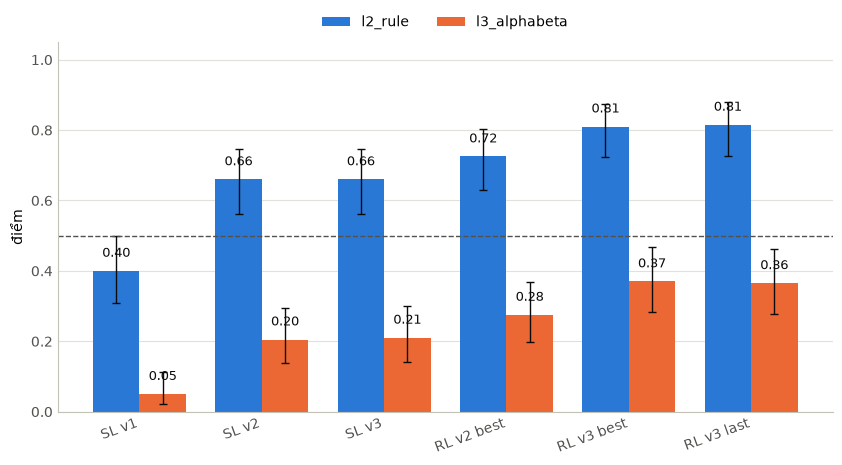

In [8]:
names = list(table.index)
fig, ax = plt.subplots(figsize=(10, 4.8))
w = 0.38
for j, (opp, color) in enumerate(zip(OPPONENTS, (PALETTE[0], PALETTE[1]), strict=True)):
    r = res[res.opponent == opp].set_index("checkpoint").reindex(names)
    x = np.arange(len(names)) + (j - 0.5) * w
    ax.bar(x, r.score, w, color=color, label=opp.split("/")[-1])
    ax.errorbar(x, r.score, yerr=[r.score - r.ci_low, r.ci_high - r.score], fmt="none", ecolor=INK, lw=1, capsize=3)
    for xi, v in zip(x, r.score, strict=True):
        ax.text(xi, v + 0.04, f"{v:.2f}", ha="center", color=INK, fontsize=9)
ax.axhline(0.5, color=MUTED, ls="--", lw=1)
ax.set_xticks(range(len(names)), names, rotation=20, ha="right"); ax.set_ylim(0, 1.05)
ax.set_ylabel("điểm"); ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0)); style(ax)
plt.show()

## 4. Kiểm tra value head

Chỉ chạy nếu có `runs/data/expert_v2`. Dữ liệu lưu nhãn tuyệt đối (+1 nếu X thắng); đổi sang góc nhìn người đang đi rồi đo MSE tách theo bên đi. Quy ước đúng thì **MSE hai bên bằng nhau** và tương quan **dương** ở cả hai; lệch dấu thì bên O đi có MSE cao và tương quan âm.

In [9]:
data_path = Path("runs/data/expert_v2/expert_dataset.npz")
if not data_path.exists():
    print("không có", data_path, "- bỏ qua")
else:
    d = np.load(data_path)
    s, v, g = d["states"], d["values"], d["game_ids"]
    u = np.random.default_rng(42).permutation(np.unique(g))          # cùng cách chia ván với train_sl
    idx = np.where(np.isin(g, u[int(len(u) * 0.9):]))[0][:20000]       # tập test
    X = torch.tensor(s[idx].astype(np.float32))
    x_turn = s[idx][:, 2, 0, 0] == 1
    y_rel = v[idx] * np.where(x_turn, 1.0, -1.0)
    out = []
    for name, path in CHECKPOINTS.items():
        if not Path(path).exists():
            continue
        net = load_net(path)
        with torch.no_grad():
            p = torch.cat([net(X[i:i + 2048].to(DEVICE))[1].squeeze(-1).cpu() for i in range(0, len(X), 2048)]).numpy()
        row = {"checkpoint": name}
        for side, m in (("X đi", x_turn), ("O đi", ~x_turn)):
            row[f"MSE {side}"] = ((p[m] - y_rel[m]) ** 2).mean()
            row[f"corr {side}"] = np.corrcoef(p[m], y_rel[m])[0, 1]
        out.append(row)
    display(pd.DataFrame(out).set_index("checkpoint"))

,MSE X đi,corr X đi,MSE O đi,corr O đi
checkpoint,,,,
SL v1,0.842,0.377,1.997,-0.404
SL v2,0.425,0.711,2.250,-0.707
SL v3,0.372,0.752,0.380,0.752
RL v2 best,0.462,0.688,0.529,0.629
RL v3 best,0.412,0.721,0.416,0.726
RL v3 last,0.414,0.721,0.414,0.726
